In [1]:
from database import postgres_connection

conn = postgres_connection()

In [2]:
import pandas as pd
import numpy as np

In [3]:
# data =  pd.read_sql(sql = 
# """select * from public.user_data u
# left join public.feed_data f on u.user_id=f.user_id
# left join public.post_text_df p on p.post_id = f.post_id
# where action = 'view' 
# order by u.user_id limit 2000000""", con = conn)

In [4]:
user_data = pd.read_sql(sql = 'select * from public.user_data LIMIT 5000000', con = conn)
feed_data = pd.read_sql(sql = "select * from public.feed_data where action = 'view' order by user_id LIMIT 5000000", con = conn)
post_text_df = pd.read_sql(sql = 'select * from public.post_text_df LIMIT 5000000', con = conn)

C:\Users\Max\AppData\Local\Temp\ipykernel_2500\2314649983.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  user_data = pd.read_sql(sql = 'select * from public.user_data LIMIT 5000000', con = conn)
C:\Users\Max\AppData\Local\Temp\ipykernel_2500\2314649983.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  feed_data = pd.read_sql(sql = "select * from public.feed_data where action = 'view' order by user_id LIMIT 5000000", con = conn)
C:\Users\Max\AppData\Local\Temp\ipykernel_2500\2314649983.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider 

In [5]:
post_text_df

,post_id,text,topic
0,1,UK economy facing major risks\n\nThe UK manufa...,business
1,2,Aids and climate top Davos agenda\n\nClimate c...,business
2,3,Asian quake hits European shares\n\nShares in ...,business
3,4,India power shares jump on debut\n\nShares in ...,business
4,5,Lacroix label bought by US firm\n\nLuxury good...,business
...,...,...,...
7018,7315,"OK, I would not normally watch a Farrelly brot...",movie
7019,7316,I give this movie 2 stars purely because of it...,movie
7020,7317,I cant believe this film was allowed to be mad...,movie
7021,7318,The version I saw of this film was the Blockbu...,movie


In [6]:
user_topic_stats = pd.read_sql(sql = 
"""select user_id,topic, count(*) as topic_total_post_viewed, sum(target) as topic_total_post_liked from public.feed_data f
left join public.post_text_df p on p.post_id=f.post_id
where action='view'
group by user_id,topic""", con = conn)

C:\Users\Max\AppData\Local\Temp\ipykernel_2500\2304366955.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  user_topic_stats = pd.read_sql(sql =


In [7]:
total_post_stats = pd.read_sql(sql = 
"""select post_id, count(*) as total_post_viewed, sum(target) as total_post_liked from public.feed_data
where action='view'
group by post_id""", con = conn)

C:\Users\Max\AppData\Local\Temp\ipykernel_2500\1434119832.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  total_post_stats = pd.read_sql(sql =


In [8]:
total_post_stats.head()

,post_id,total_post_viewed,total_post_liked
0,1,8508,1067
1,2,7495,637
2,3,8412,1122
3,4,8158,1171
4,5,8583,1153


In [9]:
total_user_stats = pd.read_sql(sql ="""
select user_id, count(*) as total_user_viewed, sum(target) as total_user_liked from public.feed_data
where action='view'
group by user_id
""", con = conn)

C:\Users\Max\AppData\Local\Temp\ipykernel_2500\1339931296.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  total_user_stats = pd.read_sql(sql ="""


In [10]:
user_data.head()

,user_id,gender,age,country,city,exp_group,os,source
0,200,1,34,Russia,Degtyarsk,3,Android,ads
1,201,0,37,Russia,Abakan,0,Android,ads
2,202,1,17,Russia,Smolensk,4,Android,ads
3,203,0,18,Russia,Moscow,1,iOS,ads
4,204,0,36,Russia,Anzhero-Sudzhensk,3,Android,ads


In [11]:
user_data = pd.merge(user_data, total_user_stats, how = 'left', on = 'user_id')

In [12]:
user_data

,user_id,gender,age,country,city,exp_group,os,source,total_user_viewed,total_user_liked
0,200,1,34,Russia,Degtyarsk,3,Android,ads,358,43
1,201,0,37,Russia,Abakan,0,Android,ads,690,58
2,202,1,17,Russia,Smolensk,4,Android,ads,637,87
3,203,0,18,Russia,Moscow,1,iOS,ads,321,61
4,204,0,36,Russia,Anzhero-Sudzhensk,3,Android,ads,138,23
...,...,...,...,...,...,...,...,...,...,...
163200,168548,0,36,Russia,Kaliningrad,4,Android,organic,362,20
163201,168549,0,18,Russia,Tula,2,Android,organic,252,22
163202,168550,1,41,Russia,Yekaterinburg,4,Android,organic,369,38
163203,168551,0,38,Russia,Moscow,3,iOS,organic,477,48


In [13]:
user_topic_stats.head()

,user_id,topic,topic_total_post_viewed,topic_total_post_liked
0,200,business,28,2
1,200,covid,93,9
2,200,entertainment,14,4
3,200,movie,88,15
4,200,politics,58,4


In [14]:
pivoted_df = user_topic_stats.pivot(
    index='user_id', 
    columns='topic', 
    values='topic_total_post_liked'
)

# 2. Заполняем пропуски нулями (если пользователь ни разу не лайкнул какую-то тему)
pivoted_df = pivoted_df.fillna(0).astype(int)

# 3. Переименовываем колонки в формат "{topic}_total_post_liked"
pivoted_df.columns = [f"{col}_total_post_liked" for col in pivoted_df.columns]

# 4. Возвращаем user_id из индекса обратно в обычную колонку
result_df = pivoted_df.reset_index()

# Проверяем результат
result_df.head()

,user_id,business_total_post_liked,covid_total_post_liked,entertainment_total_post_liked,movie_total_post_liked,politics_total_post_liked,sport_total_post_liked,tech_total_post_liked
0,200,2,9,4,15,4,7,2
1,201,3,11,4,33,1,2,4
2,202,1,22,1,35,15,13,0
3,203,3,13,2,25,5,11,2
4,204,1,8,1,9,1,2,1


In [15]:
user_data = pd.merge(user_data, result_df, how = 'left', on = 'user_id')

In [16]:
user_data.head()

,user_id,gender,age,country,city,exp_group,os,source,total_user_viewed,total_user_liked,business_total_post_liked,covid_total_post_liked,entertainment_total_post_liked,movie_total_post_liked,politics_total_post_liked,sport_total_post_liked,tech_total_post_liked
0,200,1,34,Russia,Degtyarsk,3,Android,ads,358,43,2,9,4,15,4,7,2
1,201,0,37,Russia,Abakan,0,Android,ads,690,58,3,11,4,33,1,2,4
2,202,1,17,Russia,Smolensk,4,Android,ads,637,87,1,22,1,35,15,13,0
3,203,0,18,Russia,Moscow,1,iOS,ads,321,61,3,13,2,25,5,11,2
4,204,0,36,Russia,Anzhero-Sudzhensk,3,Android,ads,138,23,1,8,1,9,1,2,1


In [17]:
bins = [0, 16, 21, 25, 35, 45, 100]
labels = ['Under 17', '17-21 (Peak)', '22-25', '26-35', '36-45', '46+']

# Добавляем новую категориальную колонку
user_data['age_group'] = pd.cut(user_data['age'], bins=bins, labels=labels)
user_data['age_group'] = user_data['age_group'].astype(str)

# Проверяем, сколько активностей попало в каждую группу
print(user_data['age_group'].value_counts())

# # Находим список стран, чья доля в датасете выше 1%
# top_countries = user_data['country'].value_counts(normalize=True)
# top_countries = top_countries[top_countries >= 0.01].index.tolist()

# # Если страна не входит в топ, заменяем её на 'Other'
# user_data['country_clean'] = user_data['country'].apply(lambda x: x if x in top_countries else 'Other')

# # Проверяем что получилось
# print(user_data['country_clean'].value_counts(normalize=True) * 100)

user_data.drop('country', axis=1, inplace=True)

user_data.drop('city', axis=1, inplace=True)

user_data.drop('os', axis=1, inplace=True)

# user_data.drop('os', axis=1, inplace=True)

# user_data['source'] = user_data['source'].map({'ads': 0, 'organic': 1})
user_data.drop('source', axis=1, inplace=True)

age_group
17-21 (Peak)    47040
26-35           39169
22-25           29817
36-45           22135
Under 17        14190
46+             10854
Name: count, dtype: int64


In [18]:
user_data

,user_id,gender,age,exp_group,total_user_viewed,total_user_liked,business_total_post_liked,covid_total_post_liked,entertainment_total_post_liked,movie_total_post_liked,politics_total_post_liked,sport_total_post_liked,tech_total_post_liked,age_group
0,200,1,34,3,358,43,2,9,4,15,4,7,2,26-35
1,201,0,37,0,690,58,3,11,4,33,1,2,4,36-45
2,202,1,17,4,637,87,1,22,1,35,15,13,0,17-21 (Peak)
3,203,0,18,1,321,61,3,13,2,25,5,11,2,17-21 (Peak)
4,204,0,36,3,138,23,1,8,1,9,1,2,1,36-45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163200,168548,0,36,4,362,20,1,6,2,7,1,0,3,36-45
163201,168549,0,18,2,252,22,0,5,0,6,7,4,0,17-21 (Peak)
163202,168550,1,41,4,369,38,1,10,2,22,0,1,2,36-45
163203,168551,0,38,3,477,48,1,16,3,22,1,4,1,36-45


In [19]:
post_text_df = pd.merge(post_text_df, total_post_stats, how = 'left', on = 'post_id')


In [20]:
post_text_df.head()

,post_id,text,topic,total_post_viewed,total_post_liked
0,1,UK economy facing major risks\n\nThe UK manufa...,business,8508.0,1067.0
1,2,Aids and climate top Davos agenda\n\nClimate c...,business,7495.0,637.0
2,3,Asian quake hits European shares\n\nShares in ...,business,8412.0,1122.0
3,4,India power shares jump on debut\n\nShares in ...,business,8158.0,1171.0
4,5,Lacroix label bought by US firm\n\nLuxury good...,business,8583.0,1153.0


In [21]:
# ==========================================
unique_texts = post_text_df['text'].dropna().drop_duplicates()

# Создаем временный DataFrame для уникальных постов, где и проведем все расчеты
text_metrics = unique_texts.to_frame()

# ==========================================
# ШАГ 2: Считаем метрики на маленьком датасете
# ==========================================

# 1. Длина текста (быстрый встроенный метод)
text_metrics['text_length'] = text_metrics['text'].str.len()

# 2. Количество слов (быстрый регулярный метод)
# Переводим в тип 'Int64' (с большой буквы), чтобы избежать проблем с типами данных
text_metrics['word_count'] = text_metrics['text'].str.split().str.len().astype('Int64')

# 3. Количество уникальных слов (считаем один раз для каждого уникального поста)
text_metrics['unique_word_count'] = text_metrics['text'].apply(lambda x: len(set(x.split()))).astype('Int64')

# ==========================================
# ШАГ 3: Быстро переносим (маппим) результаты на весь большой DataFrame data
# ==========================================

# Создаем словари «текст -> метрика» для мгновенного переноса данных
length_map = text_metrics.set_index('text')['text_length']
word_count_map = text_metrics.set_index('text')['word_count']
unique_word_map = text_metrics.set_index('text')['unique_word_count']

# Применяем словари ко всему огромному датасету (это займет доли секунды)
post_text_df['text_length'] = post_text_df['text'].map(length_map)
post_text_df['word_count'] = post_text_df['text'].map(word_count_map)
post_text_df['unique_word_count'] = post_text_df['text'].map(unique_word_map)

# Проверяем результат
print("Расчет окончен успешно!")
print(post_text_df[['text', 'text_length', 'word_count', 'unique_word_count']].head())


from sklearn.feature_extraction.text import TfidfVectorizer
# 1. Обучаем векторизатор только на УНИКАЛЬНЫХ текстах (экономим память)
unique_posts = post_text_df[['text']].dropna().drop_duplicates().copy()

# На практике лучше ограничить max_features (например, до 5000), 
# чтобы не учитывать редкие опечатки и мусорные слова
tfidf = TfidfVectorizer() 
tfidf_matrix_unique = tfidf.fit_transform(unique_posts['text'])

# 2. Считаем среднее значение TF-IDF для каждого уникального текста
# axis=1 означает, что мы усредняем значения внутри каждой строки (для каждого поста)
# .A1 превращает матрицу размера (N, 1) в обычный плоский одномерный массив NumPy
unique_posts['mean_tfidf'] = tfidf_matrix_unique.mean(axis=1).A1

# 3. Мгновенно переносим (маппим) готовые средние значения на ваш огромный датасет data
text_to_tfidf_map = unique_posts.set_index('text')['mean_tfidf']
post_text_df['mean_tfidf'] = post_text_df['text'].map(text_to_tfidf_map)

print("Расчет среднего TF-IDF успешно завершен!")
print(post_text_df[['text', 'mean_tfidf']].head())

Расчет окончен успешно!
                                                text  text_length  word_count  \
0  UK economy facing major risks\n\nThe UK manufa...         1967         324   
1  Aids and climate top Davos agenda\n\nClimate c...         2701         448   
2  Asian quake hits European shares\n\nShares in ...         3408         546   
3  India power shares jump on debut\n\nShares in ...         1026         173   
4  Lacroix label bought by US firm\n\nLuxury good...          889         150   

   unique_word_count  
0                197  
1                280  
2                329  
3                113  
4                104  
Расчет среднего TF-IDF успешно завершен!
                                                text  mean_tfidf
0  UK economy facing major risks\n\nThe UK manufa...    0.000205
1  Aids and climate top Davos agenda\n\nClimate c...    0.000261
2  Asian quake hits European shares\n\nShares in ...    0.000275
3  India power shares jump on debut\n\nShares in .

In [22]:
post_text_df

,post_id,text,topic,total_post_viewed,total_post_liked,text_length,word_count,unique_word_count,mean_tfidf
0,1,UK economy facing major risks\n\nThe UK manufa...,business,8508.0,1067.0,1967,324,197,0.000205
1,2,Aids and climate top Davos agenda\n\nClimate c...,business,7495.0,637.0,2701,448,280,0.000261
2,3,Asian quake hits European shares\n\nShares in ...,business,8412.0,1122.0,3408,546,329,0.000275
3,4,India power shares jump on debut\n\nShares in ...,business,8158.0,1171.0,1026,173,113,0.000153
4,5,Lacroix label bought by US firm\n\nLuxury good...,business,8583.0,1153.0,889,150,104,0.000149
...,...,...,...,...,...,...,...,...,...
7018,7315,"OK, I would not normally watch a Farrelly brot...",movie,16940.0,2619.0,803,159,108,0.000168
7019,7316,I give this movie 2 stars purely because of it...,movie,6572.0,677.0,800,150,111,0.000172
7020,7317,I cant believe this film was allowed to be mad...,movie,6803.0,731.0,636,111,89,0.000141
7021,7318,The version I saw of this film was the Blockbu...,movie,6785.0,680.0,728,140,97,0.000166


In [23]:
feed_data

,timestamp,user_id,post_id,action,target
0,2021-11-30 09:39:03,200,860,view,1
1,2021-10-02 14:02:19,200,5057,view,0
2,2021-10-02 14:02:31,200,4872,view,0
3,2021-10-02 14:03:48,200,5431,view,0
4,2021-10-02 14:05:32,200,6829,view,0
...,...,...,...,...,...
4999995,2021-10-29 13:33:52,12104,2649,view,0
4999996,2021-10-29 13:31:30,12104,4105,view,0
4999997,2021-10-29 13:29:30,12104,4090,view,0
4999998,2021-10-29 13:27:06,12104,4041,view,0


In [24]:
data = pd.merge(feed_data,user_data, how = 'left', on = 'user_id')
data = pd.merge(data, post_text_df, how = 'left', on = 'post_id')

In [25]:
data.head()

,timestamp,user_id,post_id,action,target,gender,age,exp_group,total_user_viewed,total_user_liked,...,tech_total_post_liked,age_group,text,topic,total_post_viewed,total_post_liked,text_length,word_count,unique_word_count,mean_tfidf
0,2021-11-30 09:39:03,200,860,view,1,1,34,3,358,43,...,2,26-35,Oscars race enters final furlong\n\nThe race f...,entertainment,8714.0,1115.0,1856,317,201,0.000219
1,2021-10-02 14:02:19,200,5057,view,0,1,34,3,358,43,...,2,26-35,the real plot...A group of post-Civil War pros...,movie,7211.0,660.0,597,106,79,0.000144
2,2021-10-02 14:02:31,200,4872,view,0,1,34,3,358,43,...,2,26-35,Perhaps Im being too generous when I give this...,movie,6600.0,698.0,2519,445,280,0.000251
3,2021-10-02 14:03:48,200,5431,view,0,1,34,3,358,43,...,2,26-35,I question anyone saying they dont care for th...,movie,6469.0,629.0,1356,240,162,0.000206
4,2021-10-02 14:05:32,200,6829,view,0,1,34,3,358,43,...,2,26-35,A recent post here by a woman claiming a milit...,movie,6685.0,679.0,1036,178,138,0.000198


In [26]:
data.groupby(['age','topic']).count()['user_id']

age  topic        
14   business          3485
     covid            19597
     entertainment     3020
     movie            32274
     politics          6973
                      ...  
78   entertainment       11
     movie               49
     politics            11
     sport               10
     tech                 9
Name: user_id, Length: 448, dtype: int64

In [27]:
pd.to_datetime(data['timestamp']).dt.hour.value_counts().sort_index()

timestamp
0          7
6     185690
7     296567
8     292825
9     288012
10    293479
11    293382
12    301302
13    292798
14    291495
15    289811
16    293428
17    290137
18    296422
19    297162
20    297764
21    298702
22    293585
23    107432
Name: count, dtype: int64

In [28]:
data['timestamp']=pd.to_datetime(data['timestamp'])

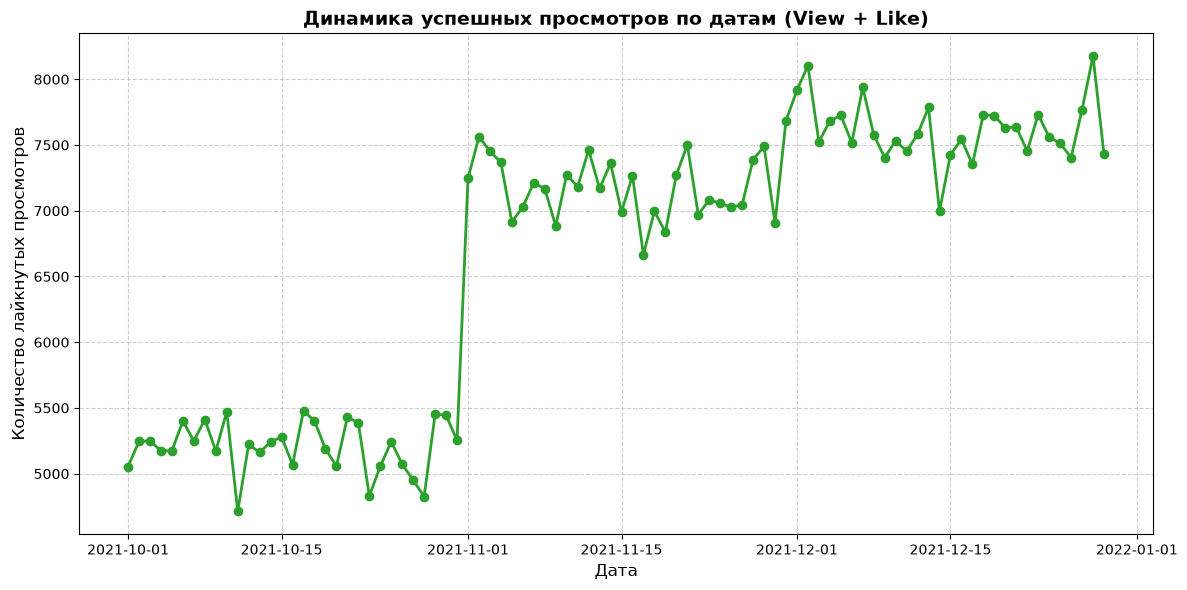

In [29]:
import matplotlib.pyplot as plt

# 1. Фильтруем данные: оставляем только успешные просмотры (action == 'view' и target == 1)
# Примечание: условие target == 1 автоматически исключает строки с NaN (лайки)
successful_views = data[(data['action'] == 'view') & (data['target'] == 1)].copy()

# 2. Извлекаем только дату
successful_views['date'] = successful_views['timestamp'].dt.date

# 3. Группируем по дате и считаем количество успешных просмотров для каждого дня
success_activity_by_date = successful_views.groupby('date').size()

# 4. Строим линейный график
plt.figure(figsize=(12, 6))
success_activity_by_date.plot(kind='line', marker='o', color='#2ca02c', linewidth=2)

# Настраиваем внешний вид
plt.title('Динамика успешных просмотров по датам (View + Like)', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество лайкнутых просмотров', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

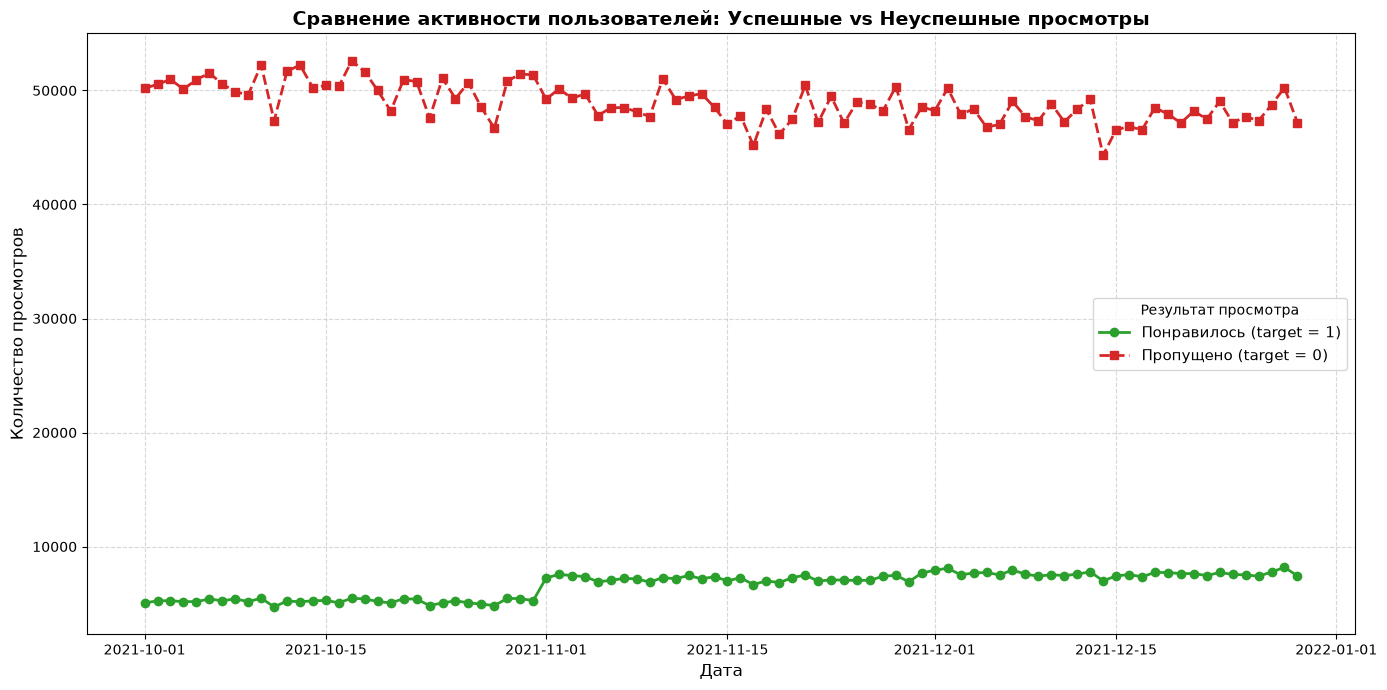

In [30]:
import matplotlib.pyplot as plt

# 1. Оставляем только события просмотров (автоматически отсекает строки-лайки, где target = NaN)
views_data = data[data['action'] == 'view'].copy()

# 2. Извлекаем только дату
views_data['date'] = views_data['timestamp'].dt.date

# 3. Группируем по дате и target, считаем количество и разворачиваем в таблицу
# Получим таблицу, где индексы — даты, а колонки — 0.0 и 1.0
views_by_date = views_data.groupby(['date', 'target']).size().unstack(fill_value=0)

# 4. Строим график с двумя линиями
plt.figure(figsize=(14, 7))

# Линия для target = 1 (успешные просмотры)
plt.plot(views_by_date.index, views_by_date[1.0], 
         marker='o', color='#2ca02c', linewidth=2, label='Понравилось (target = 1)')

# Линия для target = 0 (просмотры без лайка)
plt.plot(views_by_date.index, views_by_date[0.0], 
         marker='s', color='#d62728', linewidth=2, linestyle='--', label='Пропущено (target = 0)')

# Настраиваем внешний вид
plt.title('Сравнение активности пользователей: Успешные vs Неуспешные просмотры', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество просмотров', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Результат просмотра', fontsize=11)

# Автоматически выравниваем элементы и показываем график
plt.tight_layout()
plt.show()

C:\Users\Max\AppData\Local\Temp\ipykernel_2500\1627444293.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


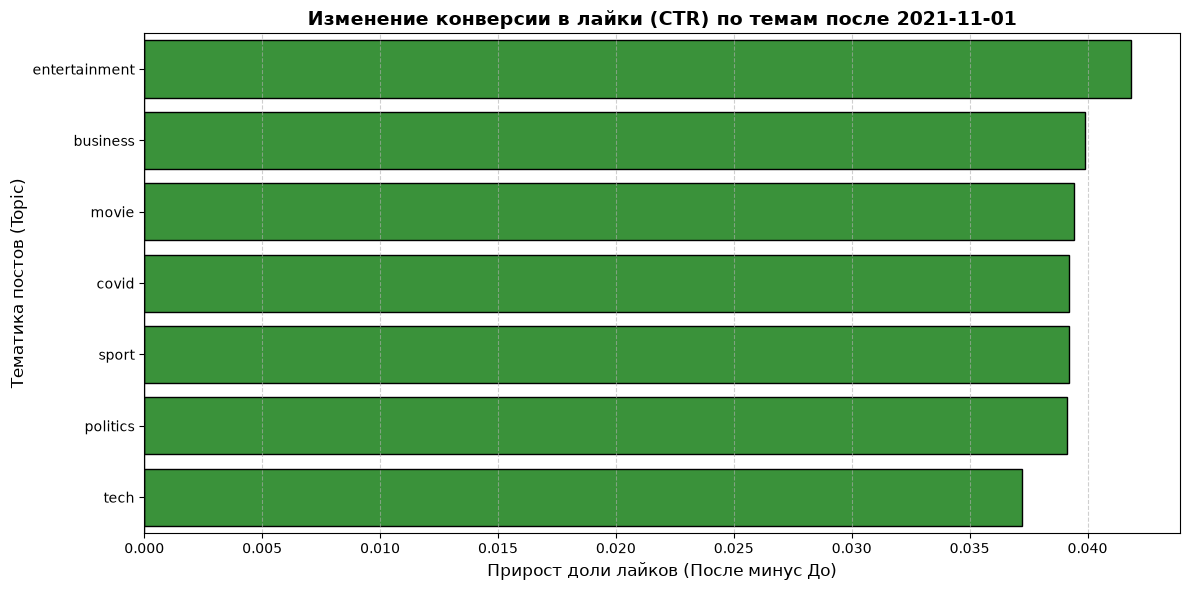

Топ тем по абсолютному приросту CTR:
        topic  ctr_growth
entertainment    0.041831
     business    0.039907
        movie    0.039432
        covid    0.039202
        sport    0.039194
     politics    0.039114
         tech    0.037217


In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Оставляем только просмотры и переводим дату в формат datetime для фильтрации
views_data = data[data['action'] == 'view'].copy()
views_data['timestamp'] = pd.to_datetime(views_data['timestamp'])

# Граничная дата перелома тренда (сверяем с графиком: 2021 год)
pivot_date = pd.to_datetime('2021-11-01')

# 2. Разделяем датасет на два периода
before_pivot = views_data[views_data['timestamp'] < pivot_date]
after_pivot = views_data[views_data['timestamp'] >= pivot_date]

# 3. Считаем средний CTR (долю лайков target=1) для каждой темы в обоих периодах
ctr_before = before_pivot.groupby('topic')['target'].mean()
ctr_after = after_pivot.groupby('topic')['target'].mean()

# 4. Объединяем и находим чистый прирост (разницу)
topic_diff = (ctr_after - ctr_before).reset_index(name='ctr_growth')

# Сортируем по убыванию прироста, чтобы самые выросшие темы были вверху
topic_diff = topic_diff.sort_values(by='ctr_growth', ascending=False)

# 5. Строим график прироста
plt.figure(figsize=(12, 6))

# Используем разные цвета для роста (зеленый) и падения (красный), если они есть
colors = ['#2ca02c' if x > 0 else '#d62728' for x in topic_diff['ctr_growth']]

sns.barplot(
    x='ctr_growth', 
    y='topic', 
    data=topic_diff, 
    palette=colors, 
    edgecolor='black'
)

# Настраиваем внешний вид
plt.title('Изменение конверсии в лайки (CTR) по темам после 2021-11-01', fontsize=14, fontweight='bold')
plt.xlabel('Прирост доли лайков (После минус До)', fontsize=12)
plt.ylabel('Тематика постов (Topic)', fontsize=12)
plt.axvline(0, color='black', linestyle='-', linewidth=1) # линия нуля
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Выведем точные цифры в консоль
print("Топ тем по абсолютному приросту CTR:")
print(topic_diff.to_string(index=False))

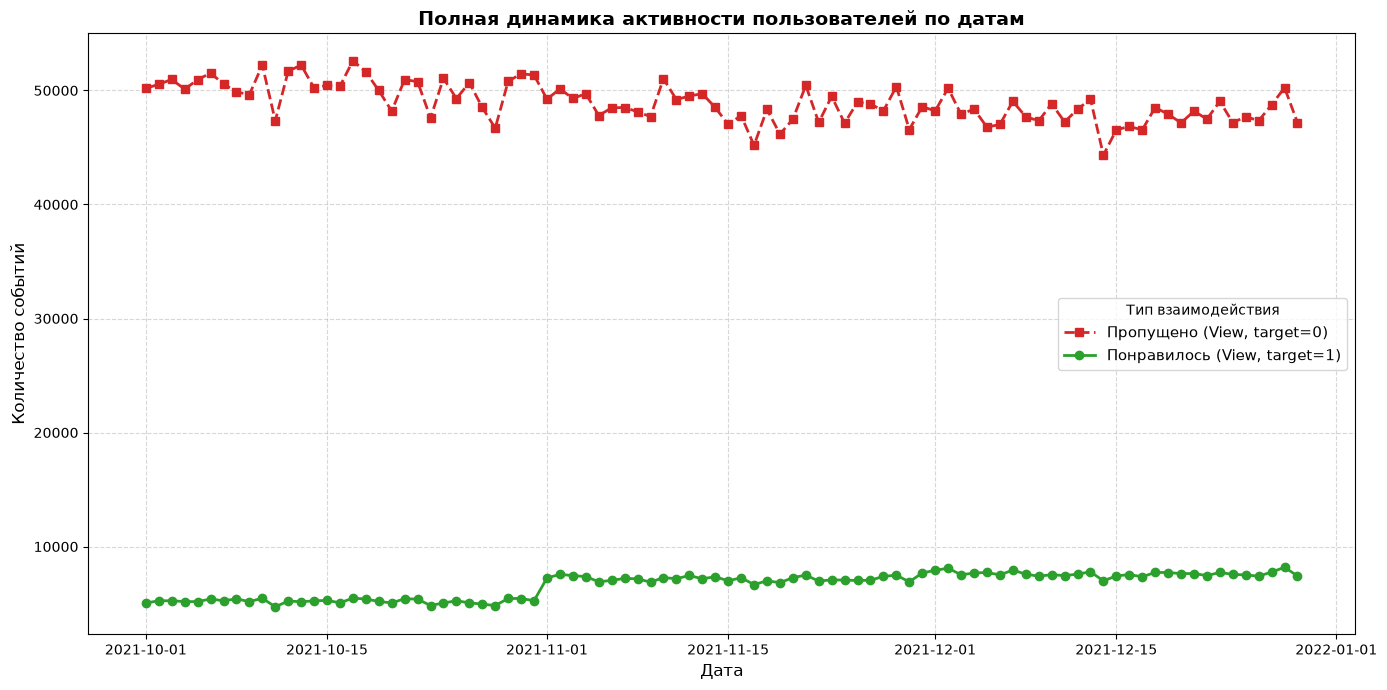

In [32]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Извлекаем дату из timestamp (создаем копию, чтобы не портить исходный df)
plot_data = data.copy()
plot_data['date'] = plot_data['timestamp'].dt.date

# 2. Создаем понятную текстовую категорию для каждого типа события
# Используем np.select или обычный loc для разметки трех линий
plot_data['event_type'] = 'unknown'
plot_data.loc[(plot_data['action'] == 'view') & (plot_data['target'] == 0), 'event_type'] = 'Просмотр (без лайка)'
plot_data.loc[(plot_data['action'] == 'view') & (plot_data['target'] == 1), 'event_type'] = 'Просмотр -> Лайк'
plot_data.loc[plot_data['action'] == 'like', 'event_type'] = 'Событие Like'

# 3. Группируем по дате и нашему новому типу события, затем разворачиваем в колонки
counts_by_date = plot_data.groupby(['date', 'event_type']).size().unstack(fill_value=0)

# 4. Строим график со всеми тремя линиями
plt.figure(figsize=(14, 7))

# Линия 1: Просмотры без лайка (target=0)
if 'Просмотр (без лайка)' in counts_by_date.columns:
    plt.plot(counts_by_date.index, counts_by_date['Просмотр (без лайка)'], 
             marker='s', color='#d62728', linewidth=2, linestyle='--', label='Пропущено (View, target=0)')

# Линия 2: Просмотры с лайком (target=1)
if 'Просмотр -> Лайк' in counts_by_date.columns:
    plt.plot(counts_by_date.index, counts_by_date['Просмотр -> Лайк'], 
             marker='o', color='#2ca02c', linewidth=2, label='Понравилось (View, target=1)')

# Линия 3: Чистые события лайков (action='like')
if 'Событие Like' in counts_by_date.columns:
    plt.plot(counts_by_date.index, counts_by_date['Событие Like'], 
             marker='^', color='#ff7f0e', linewidth=2, linestyle=':', label='Прямые лайки (Action=Like)')

# Настраиваем внешний вид графиков
plt.title('Полная динамика активности пользователей по датам', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество событий', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Тип взаимодействия', fontsize=11)

plt.tight_layout()
plt.show()

In [33]:
import pandas as pd

# 1. Группируем и находим топ-5 дней с наименьшей активностью
data['date']=data['timestamp'].dt.date
daily_activity = data.groupby('date').size()
lowest_days = daily_activity.sort_values().head(5)

# 2. Превращаем результат в DataFrame для удобства работы
df_lowest = lowest_days.reset_index(name='activity_count')

# 3. Переводим обратно в формат datetime, чтобы извлечь день недели
df_lowest['date'] = pd.to_datetime(df_lowest['date'])

# 4. Получаем номер дня недели (0 = Понедельник, 6 = Воскресенье)
df_lowest['weekday_num'] = df_lowest['date'].dt.weekday

# Словарь для перевода на русский язык
ru_weekdays = {
    0: 'Понедельник', 1: 'Вторник', 2: 'Среда', 
    3: 'Четверг', 4: 'Пятница', 5: 'Суббота', 6: 'Воскресенье'
}

# 5. Маппим названия дней недели
df_lowest['day_of_week'] = df_lowest['weekday_num'].map(ru_weekdays)

# Оставляем только нужные колонки для вывода
result = df_lowest[['date', 'day_of_week', 'activity_count']]
print(result.to_string(index=False))

      date day_of_week  activity_count
2021-12-14     Вторник           51322
2021-10-28     Четверг           51517
2021-11-17       Среда           51853
2021-10-11 Понедельник           52055
2021-10-23     Суббота           52417


In [34]:
# 1. Извлекаем номер дня недели (0 = Понедельник, 6 = Воскресенье)
data['weekday_num'] = data['timestamp'].dt.weekday

# 2. Группируем по номеру дня и считаем количество активностей
weekday_activity = data.groupby('weekday_num').size()

# Словарь для красивого отображения названий на русском
ru_weekdays = {
    0: 'Понедельник', 1: 'Вторник', 2: 'Среда', 
    3: 'Четверг', 4: 'Пятница', 5: 'Суббота', 6: 'Воскресенье'
}

# 3. Переименовываем индексы с чисел на названия дней недели
weekday_activity.index = weekday_activity.index.map(ru_weekdays)

# Выводим результат
print("Активность пользователей по дням недели:")
print(weekday_activity)

Активность пользователей по дням недели:
weekday_num
Понедельник    715212
Вторник        726699
Среда          717047
Четверг        668201
Пятница        719660
Суббота        720271
Воскресенье    732910
dtype: int64


In [35]:
data.drop('weekday_num', axis=1, inplace=True)

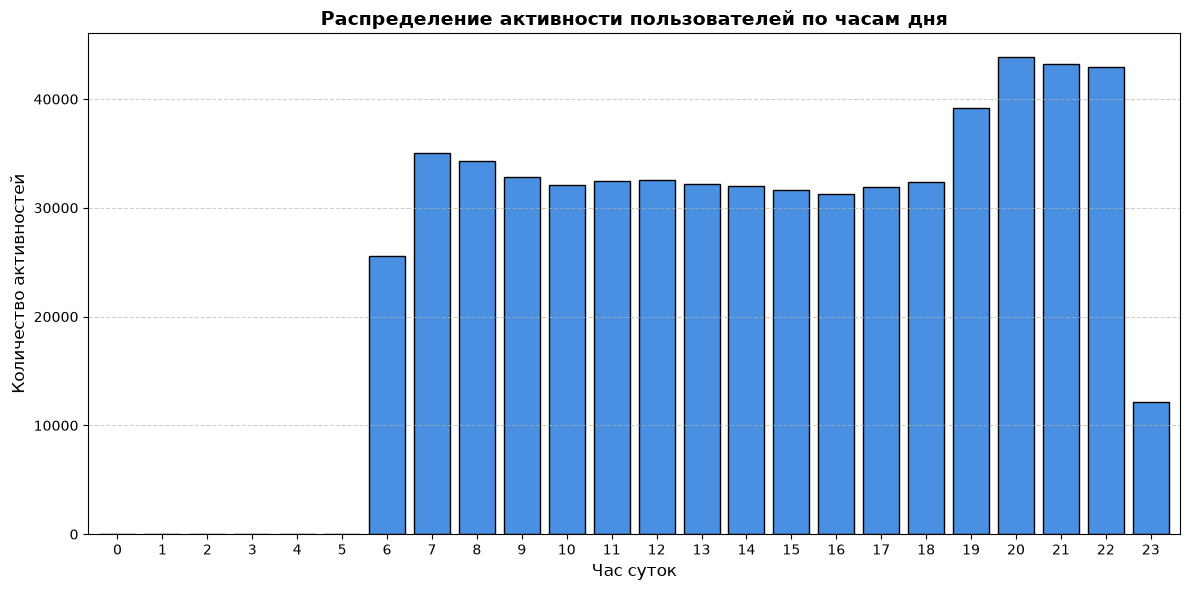

In [36]:
import matplotlib.pyplot as plt

# 1. Извлекаем час (значения от 0 до 23)
data['hour'] = data['timestamp'].dt.hour

# 2. Группируем по часам и считаем количество активностей
hourly_activity = data[(data['action']=='view') & (data['target']==1)].groupby('hour').size()

# 3. Гарантируем, что на графике будут отображаться все 24 часа, даже если в какой-то час не было действий
hourly_activity = hourly_activity.reindex(range(24), fill_value=0)

# 4. Строим столбчатый график
plt.figure(figsize=(12, 6))
hourly_activity.plot(kind='bar', color='#4a90e2', edgecolor='black', width=0.8)

# Настройка внешнего вида
plt.title('Распределение активности пользователей по часам дня', fontsize=14, fontweight='bold')
plt.xlabel('Час суток', fontsize=12)
plt.ylabel('Количество активностей', fontsize=12)
plt.xticks(rotation=0) # Часы будут написаны горизонтально
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 5. Чистим за собой DataFrame и удаляем временную колонку 'hour'
data.drop(columns=['hour'], inplace=True)

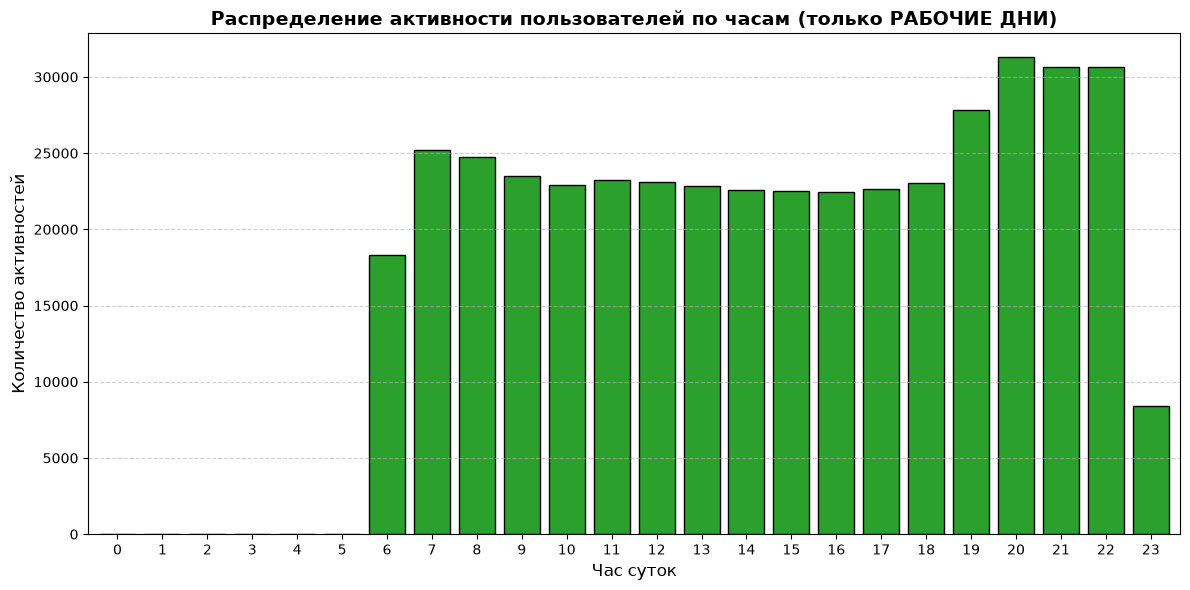

In [37]:
# 1. Извлекаем номер дня недели и час
data['weekday_num'] = data['timestamp'].dt.weekday
data['hour'] = data['timestamp'].dt.hour

# 2. Фильтруем: оставляем только рабочие дни (0, 1, 2, 3, 4)
working_days_data = data[(data['action']=='view') & (data['target']==1) & (data['weekday_num'] < 5)]

# 3. Группируем по часам для рабочих дней и заполняем возможные пропуски нулями
hourly_activity_workdays = working_days_data.groupby('hour').size()
hourly_activity_workdays = hourly_activity_workdays.reindex(range(24), fill_value=0)

# 4. Строим график
plt.figure(figsize=(12, 6))
hourly_activity_workdays.plot(kind='bar', color='#2ca02c', edgecolor='black', width=0.8)

# Настройка внешнего вида
plt.title('Распределение активности пользователей по часам (только РАБОЧИЕ ДНИ)', fontsize=14, fontweight='bold')
plt.xlabel('Час суток', fontsize=12)
plt.ylabel('Количество активностей', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 5. Удаляем временные колонки из исходного DataFrame
data.drop(columns=['weekday_num', 'hour'], inplace=True)

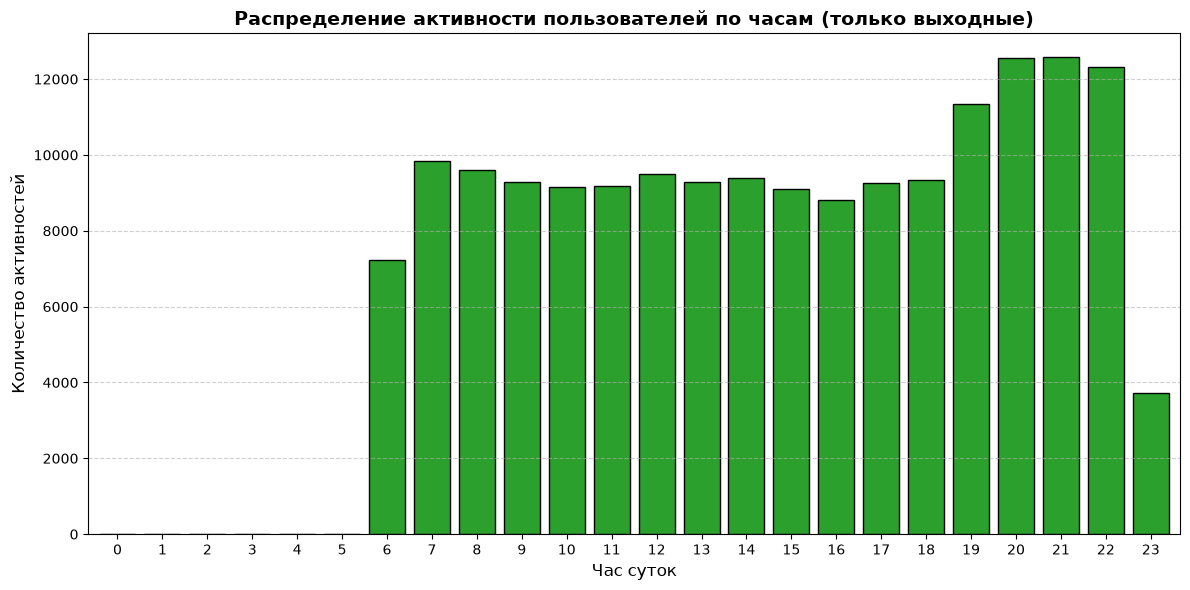

In [38]:
# 1. Извлекаем номер дня недели и час
data['weekday_num'] = data['timestamp'].dt.weekday
data['hour'] = data['timestamp'].dt.hour

# 2. Фильтруем: оставляем только рабочие дни (0, 1, 2, 3, 4)
working_days_data = data[(data['action']=='view') & (data['target']==1) & (data['weekday_num'] > 4)]

# 3. Группируем по часам для рабочих дней и заполняем возможные пропуски нулями
hourly_activity_workdays = working_days_data.groupby('hour').size()
hourly_activity_workdays = hourly_activity_workdays.reindex(range(24), fill_value=0)

# 4. Строим график
plt.figure(figsize=(12, 6))
hourly_activity_workdays.plot(kind='bar', color='#2ca02c', edgecolor='black', width=0.8)

# Настройка внешнего вида
plt.title('Распределение активности пользователей по часам (только выходные)', fontsize=14, fontweight='bold')
plt.xlabel('Час суток', fontsize=12)
plt.ylabel('Количество активностей', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 5. Удаляем временные колонки из исходного DataFrame
data.drop(columns=['weekday_num', 'hour'], inplace=True)

In [39]:
data['is_weekend']=data['timestamp'].dt.weekday.isin([5,6])
data['hour']=data['timestamp'].dt.hour
data['period_of_day'] = data['hour'].apply(lambda x: 'night' if x < 5 else ('morning' if x < 12 else ('afternoon' if x < 18 else 'evening')))

In [40]:
data.drop('timestamp', axis=1, inplace=True)

In [41]:
data.head()

,user_id,post_id,action,target,gender,age,exp_group,total_user_viewed,total_user_liked,business_total_post_liked,...,total_post_viewed,total_post_liked,text_length,word_count,unique_word_count,mean_tfidf,date,is_weekend,hour,period_of_day
0,200,860,view,1,1,34,3,358,43,2,...,8714.0,1115.0,1856,317,201,0.000219,2021-11-30,False,9,morning
1,200,5057,view,0,1,34,3,358,43,2,...,7211.0,660.0,597,106,79,0.000144,2021-10-02,True,14,afternoon
2,200,4872,view,0,1,34,3,358,43,2,...,6600.0,698.0,2519,445,280,0.000251,2021-10-02,True,14,afternoon
3,200,5431,view,0,1,34,3,358,43,2,...,6469.0,629.0,1356,240,162,0.000206,2021-10-02,True,14,afternoon
4,200,6829,view,0,1,34,3,358,43,2,...,6685.0,679.0,1036,178,138,0.000198,2021-10-02,True,14,afternoon


In [42]:
data.drop('date', axis=1, inplace=True)

In [43]:
data.head()

,user_id,post_id,action,target,gender,age,exp_group,total_user_viewed,total_user_liked,business_total_post_liked,...,topic,total_post_viewed,total_post_liked,text_length,word_count,unique_word_count,mean_tfidf,is_weekend,hour,period_of_day
0,200,860,view,1,1,34,3,358,43,2,...,entertainment,8714.0,1115.0,1856,317,201,0.000219,False,9,morning
1,200,5057,view,0,1,34,3,358,43,2,...,movie,7211.0,660.0,597,106,79,0.000144,True,14,afternoon
2,200,4872,view,0,1,34,3,358,43,2,...,movie,6600.0,698.0,2519,445,280,0.000251,True,14,afternoon
3,200,5431,view,0,1,34,3,358,43,2,...,movie,6469.0,629.0,1356,240,162,0.000206,True,14,afternoon
4,200,6829,view,0,1,34,3,358,43,2,...,movie,6685.0,679.0,1036,178,138,0.000198,True,14,afternoon


In [44]:
# data.drop('post_id', axis=1, inplace=True)

In [45]:
data.head()

,user_id,post_id,action,target,gender,age,exp_group,total_user_viewed,total_user_liked,business_total_post_liked,...,topic,total_post_viewed,total_post_liked,text_length,word_count,unique_word_count,mean_tfidf,is_weekend,hour,period_of_day
0,200,860,view,1,1,34,3,358,43,2,...,entertainment,8714.0,1115.0,1856,317,201,0.000219,False,9,morning
1,200,5057,view,0,1,34,3,358,43,2,...,movie,7211.0,660.0,597,106,79,0.000144,True,14,afternoon
2,200,4872,view,0,1,34,3,358,43,2,...,movie,6600.0,698.0,2519,445,280,0.000251,True,14,afternoon
3,200,5431,view,0,1,34,3,358,43,2,...,movie,6469.0,629.0,1356,240,162,0.000206,True,14,afternoon
4,200,6829,view,0,1,34,3,358,43,2,...,movie,6685.0,679.0,1036,178,138,0.000198,True,14,afternoon


In [46]:
# data[data['country']=='Russia'].groupby(['country','city']).count()['user_id']

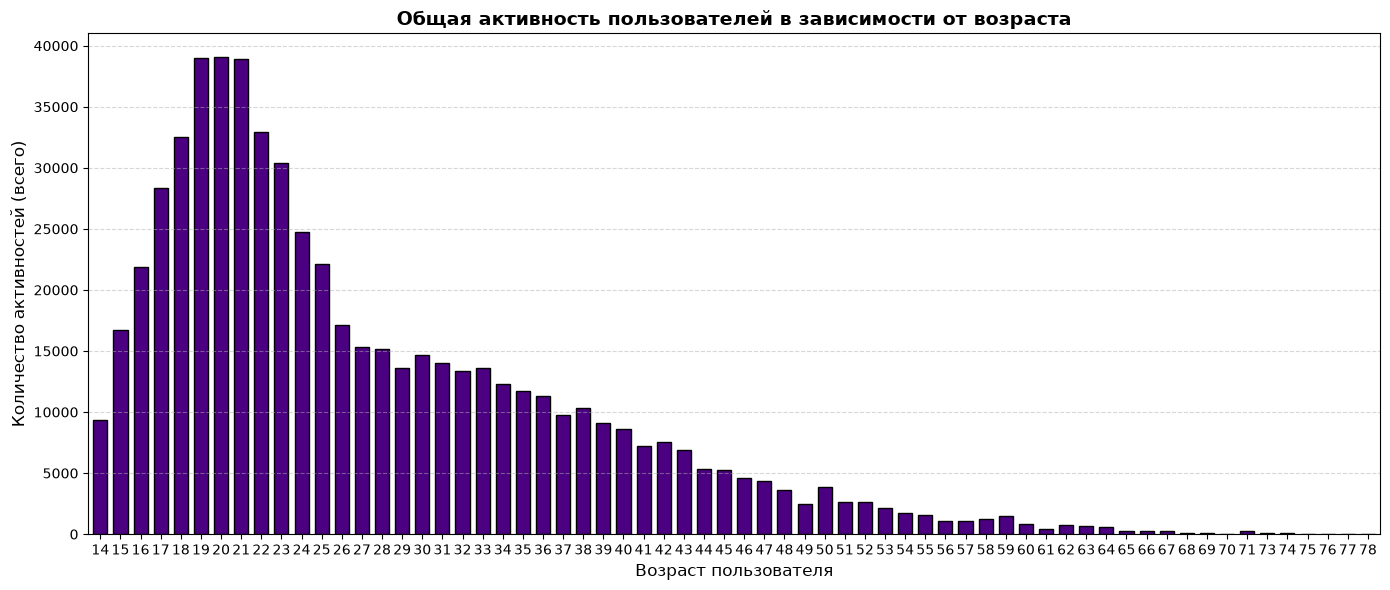

In [47]:

# 1. Группируем данные по возрасту и считаем количество строк
activity_by_age = data[(data['action']=='view') & (data['target']==1)].groupby('age').size()

# 2. Строим график
plt.figure(figsize=(14, 6))
activity_by_age.plot(kind='bar', color='#4b0082', edgecolor='black', width=0.7)

# Настраиваем внешний вид
plt.title('Общая активность пользователей в зависимости от возраста', fontsize=14, fontweight='bold')
plt.xlabel('Возраст пользователя', fontsize=12)
plt.ylabel('Количество активностей (всего)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=0)  # Возраст будет написан прямо, без наклона

plt.tight_layout()
plt.show()



In [48]:
# bins = [0, 16, 21, 25, 35, 45, 100]
# labels = ['Under 17', '17-21 (Peak)', '22-25', '26-35', '36-45', '46+']

# # Добавляем новую категориальную колонку
# data['age_group'] = pd.cut(data['age'], bins=bins, labels=labels)
# data['age_group'] = data['age_group'].astype(str)

# # Проверяем, сколько активностей попало в каждую группу
# print(data['age_group'].value_counts())

In [49]:
data.head()

,user_id,post_id,action,target,gender,age,exp_group,total_user_viewed,total_user_liked,business_total_post_liked,...,topic,total_post_viewed,total_post_liked,text_length,word_count,unique_word_count,mean_tfidf,is_weekend,hour,period_of_day
0,200,860,view,1,1,34,3,358,43,2,...,entertainment,8714.0,1115.0,1856,317,201,0.000219,False,9,morning
1,200,5057,view,0,1,34,3,358,43,2,...,movie,7211.0,660.0,597,106,79,0.000144,True,14,afternoon
2,200,4872,view,0,1,34,3,358,43,2,...,movie,6600.0,698.0,2519,445,280,0.000251,True,14,afternoon
3,200,5431,view,0,1,34,3,358,43,2,...,movie,6469.0,629.0,1356,240,162,0.000206,True,14,afternoon
4,200,6829,view,0,1,34,3,358,43,2,...,movie,6685.0,679.0,1036,178,138,0.000198,True,14,afternoon


In [50]:
# country_percentages = data['country'].value_counts(normalize=True) * 100
# print(country_percentages)

In [51]:
# # Находим список стран, чья доля в датасете выше 1%
# top_countries = data['country'].value_counts(normalize=True)
# top_countries = top_countries[top_countries >= 0.01].index.tolist()

# # Если страна не входит в топ, заменяем её на 'Other'
# data['country_clean'] = data['country'].apply(lambda x: x if x in top_countries else 'Other')

# # Проверяем что получилось
# print(data['country_clean'].value_counts(normalize=True) * 100)

In [52]:
# data.head()

In [53]:
# data.drop('country', axis=1, inplace=True)

In [54]:
# data.head()

In [55]:
# # Считаем средний CTR для каждого города только по событиям просмотров
# city_ctr = data[data['action'] == 'view'].groupby('city')['target'].mean()

# # Переносим эти числовые значения в датасет
# data['city_ctr'] = data['city'].map(city_ctr)

# # Если появились NaN (для городов, где были только лайки, а не просмотры), заполняем их общим средним CTR
# data['city_ctr'].fillna(data[data['action'] == 'view']['target'].mean(), inplace=True)

In [56]:
data.columns

Index(['user_id', 'post_id', 'action', 'target', 'gender', 'age', 'exp_group',
       'total_user_viewed', 'total_user_liked', 'business_total_post_liked',
       'covid_total_post_liked', 'entertainment_total_post_liked',
       'movie_total_post_liked', 'politics_total_post_liked',
       'sport_total_post_liked', 'tech_total_post_liked', 'age_group', 'text',
       'topic', 'total_post_viewed', 'total_post_liked', 'text_length',
       'word_count', 'unique_word_count', 'mean_tfidf', 'is_weekend', 'hour',
       'period_of_day'],
      dtype='object')

In [57]:
# data.drop('city', axis=1, inplace=True)

In [58]:
# data.head()

In [59]:
# data['os'].value_counts()

In [60]:
# data['source'].value_counts()

In [61]:
# # Кодируем операционную систему
# data['os'] = data['os'].map({'Android': 0, 'iOS': 1})

# # Кодируем источник трафика
# data['source'] = data['source'].map({'ads': 0, 'organic': 1})

In [62]:
# data.head()

In [63]:
# # ==========================================
# # ШАГ 1: Выделяем только УНИКАЛЬНЫЕ тексты постов
# # ==========================================
# unique_texts = data['text'].dropna().drop_duplicates()

# # Создаем временный DataFrame для уникальных постов, где и проведем все расчеты
# text_metrics = unique_texts.to_frame()

# # ==========================================
# # ШАГ 2: Считаем метрики на маленьком датасете
# # ==========================================

# # 1. Длина текста (быстрый встроенный метод)
# text_metrics['text_length'] = text_metrics['text'].str.len()

# # 2. Количество слов (быстрый регулярный метод)
# # Переводим в тип 'Int64' (с большой буквы), чтобы избежать проблем с типами данных
# text_metrics['word_count'] = text_metrics['text'].str.split().str.len().astype('Int64')

# # 3. Количество уникальных слов (считаем один раз для каждого уникального поста)
# text_metrics['unique_word_count'] = text_metrics['text'].apply(lambda x: len(set(x.split()))).astype('Int64')

# # ==========================================
# # ШАГ 3: Быстро переносим (маппим) результаты на весь большой DataFrame data
# # ==========================================

# # Создаем словари «текст -> метрика» для мгновенного переноса данных
# length_map = text_metrics.set_index('text')['text_length']
# word_count_map = text_metrics.set_index('text')['word_count']
# unique_word_map = text_metrics.set_index('text')['unique_word_count']

# # Применяем словари ко всему огромному датасету (это займет доли секунды)
# data['text_length'] = data['text'].map(length_map)
# data['word_count'] = data['text'].map(word_count_map)
# data['unique_word_count'] = data['text'].map(unique_word_map)

# # Проверяем результат
# print("Расчет окончен успешно!")
# print(data[['text', 'text_length', 'word_count', 'unique_word_count']].head())

In [64]:
# data.head()

In [65]:
# from sklearn.feature_extraction.text import TfidfVectorizer

# # Рекомендуется ограничить количество признаков (например, до 100-200 самых важных слов),
# # чтобы не раздувать датасет до гигантских размеров
# tfidf = TfidfVectorizer(max_features=100, stop_words='english') # или 'russian', если тексты на русском

# # Обучаем TF-IDF на уникальных текстах (чтобы сэкономить память)
# # В вашей базе посты дублируются из-за логов кликов, поэтому берем только уникальные
# unique_posts = data[['text']].drop_duplicates()
# tfidf_matrix = tfidf.fit_transform(unique_posts['text'])

In [66]:
# from sklearn.feature_extraction.text import TfidfVectorizer
# # 1. Обучаем векторизатор только на УНИКАЛЬНЫХ текстах (экономим память)
# unique_posts = data[['text']].dropna().drop_duplicates().copy()

# # На практике лучше ограничить max_features (например, до 5000), 
# # чтобы не учитывать редкие опечатки и мусорные слова
# tfidf = TfidfVectorizer() 
# tfidf_matrix_unique = tfidf.fit_transform(unique_posts['text'])

# # 2. Считаем среднее значение TF-IDF для каждого уникального текста
# # axis=1 означает, что мы усредняем значения внутри каждой строки (для каждого поста)
# # .A1 превращает матрицу размера (N, 1) в обычный плоский одномерный массив NumPy
# unique_posts['mean_tfidf'] = tfidf_matrix_unique.mean(axis=1).A1

# # 3. Мгновенно переносим (маппим) готовые средние значения на ваш огромный датасет data
# text_to_tfidf_map = unique_posts.set_index('text')['mean_tfidf']
# data['mean_tfidf'] = data['text'].map(text_to_tfidf_map)

# print("Расчет среднего TF-IDF успешно завершен!")
# print(data[['text', 'mean_tfidf']].head())


In [67]:
# data.head()

In [68]:
# data.drop('text', axis=1, inplace=True)
data.drop('action', axis=1, inplace=True)

In [69]:
data.head()

,user_id,post_id,target,gender,age,exp_group,total_user_viewed,total_user_liked,business_total_post_liked,covid_total_post_liked,...,topic,total_post_viewed,total_post_liked,text_length,word_count,unique_word_count,mean_tfidf,is_weekend,hour,period_of_day
0,200,860,1,1,34,3,358,43,2,9,...,entertainment,8714.0,1115.0,1856,317,201,0.000219,False,9,morning
1,200,5057,0,1,34,3,358,43,2,9,...,movie,7211.0,660.0,597,106,79,0.000144,True,14,afternoon
2,200,4872,0,1,34,3,358,43,2,9,...,movie,6600.0,698.0,2519,445,280,0.000251,True,14,afternoon
3,200,5431,0,1,34,3,358,43,2,9,...,movie,6469.0,629.0,1356,240,162,0.000206,True,14,afternoon
4,200,6829,0,1,34,3,358,43,2,9,...,movie,6685.0,679.0,1036,178,138,0.000198,True,14,afternoon


In [70]:
data['is_weekend'] = data['is_weekend'].astype(int)

In [71]:
# data.drop('user_id', axis=1, inplace=True)
# data.drop('post_id', axis=1, inplace=True)

In [72]:
from sklearn.model_selection import train_test_split

data_ = data.drop(['target','user_id','post_id','text'], axis=1)
target = data[['target']]

X_train, X_test, y_train, y_test = train_test_split(data_,
                                                    target, 
                                                    test_size=0.25,
                                                    random_state=1)

In [73]:
print(data['topic'].value_counts(normalize=True) * 100)

topic
movie            36.93378
covid            24.17320
sport            13.33692
politics         10.13214
business          6.29066
entertainment     5.05818
tech              4.07512
Name: proportion, dtype: float64


In [74]:
X_train['age_group'].describe()

count          3750000
unique               6
top       17-21 (Peak)
freq           1108061
Name: age_group, dtype: object

In [75]:
category_columns = X_train.select_dtypes(include=['object']).columns.to_list()

In [76]:
category_columns

['age_group', 'topic', 'period_of_day']

In [77]:
X_train.select_dtypes(include=['object']).columns

Index(['age_group', 'topic', 'period_of_day'], dtype='object')

In [78]:
num_columns = X_train.columns.difference(category_columns).to_list()

In [79]:
num_columns

['age',
 'business_total_post_liked',
 'covid_total_post_liked',
 'entertainment_total_post_liked',
 'exp_group',
 'gender',
 'hour',
 'is_weekend',
 'mean_tfidf',
 'movie_total_post_liked',
 'politics_total_post_liked',
 'sport_total_post_liked',
 'tech_total_post_liked',
 'text_length',
 'total_post_liked',
 'total_post_viewed',
 'total_user_liked',
 'total_user_viewed',
 'unique_word_count',
 'word_count']

In [80]:
data.isna().sum()

user_id                           0
post_id                           0
target                            0
gender                            0
age                               0
exp_group                         0
total_user_viewed                 0
total_user_liked                  0
business_total_post_liked         0
covid_total_post_liked            0
entertainment_total_post_liked    0
movie_total_post_liked            0
politics_total_post_liked         0
sport_total_post_liked            0
tech_total_post_liked             0
age_group                         0
text                              0
topic                             0
total_post_viewed                 0
total_post_liked                  0
text_length                       0
word_count                        0
unique_word_count                 0
mean_tfidf                        0
is_weekend                        0
hour                              0
period_of_day                     0
dtype: int64

In [81]:
for col in category_columns:
    X_train[col]=X_train[col].fillna(X_train[col].mode()[0]).astype(str)
    X_test[col]=X_test[col].fillna(X_test[col].mode()[0]).astype(str)
    # data[col]=data[col].fillna(data[col].mode()[0]).astype(str)

In [82]:
for col in num_columns:
    X_train[col]=X_train[col].fillna(0)
    X_test[col]=X_test[col].fillna(0)
    # data[col]=data[col].fillna(data[col].median())

In [83]:
num_cols_idx = [list(X_train.columns).index(col) for col in num_columns]
cat_column_ohe_idx = [list(X_train.columns).index(col) for col in category_columns]
# cat_column_ohe_idx = [list(X_train.columns).index(col) for col in category_columns if X_train[col].nunique() < 5]
# cat_column_target_idx = [list(X_train.columns).index(col) for col in category_columns if X_train[col].nunique() >= 5]

In [84]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from category_encoders import TargetEncoder
from category_encoders.one_hot import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, f1_score, roc_curve, auc

t = [('StandardScaler', StandardScaler(), num_cols_idx),
     ('OneHotEncoder', OneHotEncoder(), cat_column_ohe_idx),
    #  ('TargetEncoder', TargetEncoder(), cat_column_target_idx)
    ]

column_transfor = ColumnTransformer(transformers=t)


In [85]:
X_train.columns

Index(['gender', 'age', 'exp_group', 'total_user_viewed', 'total_user_liked',
       'business_total_post_liked', 'covid_total_post_liked',
       'entertainment_total_post_liked', 'movie_total_post_liked',
       'politics_total_post_liked', 'sport_total_post_liked',
       'tech_total_post_liked', 'age_group', 'topic', 'total_post_viewed',
       'total_post_liked', 'text_length', 'word_count', 'unique_word_count',
       'mean_tfidf', 'is_weekend', 'hour', 'period_of_day'],
      dtype='object')

In [88]:
pipe_lr = Pipeline([
    ('column_transfor', column_transfor),
    ('logistic_regression', LogisticRegression(
        penalty='l2',  C=5.0,  solver='lbfgs', n_jobs=-1,max_iter=300,))
])

pipe_lr.fit(X_train, y_train)
y_pred = pipe_lr.predict(X_test)
y_pred_proba = pipe_lr.predict_proba(X_test)[:, 1]

print(f"log regression score = {pipe_lr.score(X_test,y_test):.3f}")
print(classification_report(y_test, y_pred))

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

print(f"Значение AUC: {roc_auc:.4f}")


e:\python_projects\ML_course_project2\env\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


log regression score = 0.880
              precision    recall  f1-score   support

           0       0.88      1.00      0.94   1100263
           1       0.34      0.00      0.00    149737

    accuracy                           0.88   1250000
   macro avg       0.61      0.50      0.47   1250000
weighted avg       0.82      0.88      0.82   1250000

Значение AUC: 0.6535


e:\python_projects\ML_course_project2\env\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [89]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc

pipe_gb = Pipeline([
    ('column_transfor', column_transfor),
    ('gradient_boosting', GradientBoostingClassifier(
        learning_rate=1,    # Снижаем до 0.1 (шаг 1.0 заставляет модель метаться и строить лишнее)
        n_estimators=100,      # Сокращаем количество деревьев со 100 до 50 (для теста скорости)
        max_depth=5,          # Жестко ограничиваем глубину дерева (по умолчанию 3, не увеличивайте её!)
        
        # --- ГЛАВНЫЕ ПАРАМЕТРЫ ДЛЯ УСКОРЕНИЯ ---
        subsample=0.1,        # Обучаем каждое дерево только на 10% случайных строк (стохастический бустинг).
                              # Для 3.75 млн строк это гигантское ускорение без потери качества!
        # max_features='sqrt',  # Каждое дерево ищет сплиты не по всем 115+ колонкам, а по случайному корню из них
        
        random_state=1
    ))
])

# Обучаем модель (с ravel() для убирания предупреждений)
pipe_gb.fit(X_train, y_train.values.ravel())

# y_pred = pipe_gb.predict(X_test)
# y_pred_proba = pipe_gb.predict_proba(X_test)[:, 1]

# print(f"gradient boosting score = {pipe_gb.score(X_test,y_test):.3f}")
# print(classification_report(y_test, y_pred))

# fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
# roc_auc = auc(fpr, tpr)

# print(f"Значение AUC: {roc_auc:.4f}")

,steps,"[('column_transfor', ...), ('gradient_boosting', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('StandardScaler', ...), ('OneHotEncoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [90]:
y_pred = pipe_gb.predict(X_test)
y_pred_proba = pipe_gb.predict_proba(X_test)[:, 1]

# Считаем метрики (быстрый расчет на основе готовых y_pred)
print(f"gradient boosting score = {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred))

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)
print(f"Значение AUC: {roc_auc:.4f}")

gradient boosting score = 0.877
              precision    recall  f1-score   support

           0       0.88      0.99      0.93   1100263
           1       0.27      0.02      0.03    149737

    accuracy                           0.88   1250000
   macro avg       0.58      0.51      0.48   1250000
weighted avg       0.81      0.88      0.83   1250000

Значение AUC: 0.7087


In [93]:
from sklearn.ensemble import HistGradientBoostingClassifier

pipe_hgb = Pipeline([
    ('column_transfor', column_transfor),
    ('gradient_boosting', HistGradientBoostingClassifier(
        # 1. Постепенное обучение
        learning_rate=0.05,       # Снижение шага до 0.05 или 0.03 заставляет модель точнее настраивать веса
        max_iter=250,             # Увеличиваем число итераций, так как шаг стал меньше
        
        # 2. Усложнение структуры деревьев
        max_depth=7,              # Позволяет улавливать более сложные нелинейные зависимости и взаимодействия
        max_leaf_nodes=63,        # Должно коррелировать с max_depth (обычно в пределах от 2^(depth-1) до 2^depth)
        min_samples_leaf=50,      # Защита от переобучения на мелких подвыборках (по умолчанию 20, можно поднять до 50-100)
        
        # 3. Добавление регуляризации
        l2_regularization=0.1,    # L2-регуляризация штрафует слишком большие веса в листьях, спасает от оверфиттинга
        
        # 4. Контроль остановки
        early_stopping=True,
        n_iter_no_change=15,      # Даем модели чуть больше «времени» (15 итераций вместо 10) на выход из локального плато
        validation_fraction=0.1,  # 10% данных для валидации early stopping
        
        scoring='roc_auc',        # Обучение и остановка будут ориентироваться строго на вашу целевую метрику!
        random_state=1
    ))
])
pipe_hgb.fit(X_train, y_train.values.ravel())

,steps,"[('column_transfor', ...), ('gradient_boosting', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('StandardScaler', ...), ('OneHotEncoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [94]:
y_pred = pipe_hgb.predict(X_test)
y_pred_proba = pipe_hgb.predict_proba(X_test)[:, 1]

# Считаем метрики (быстрый расчет на основе готовых y_pred)
print(f"gradient boosting score = {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred))

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)
print(f"Значение AUC: {roc_auc:.4f}")

gradient boosting score = 0.880
              precision    recall  f1-score   support

           0       0.88      1.00      0.94   1100263
           1       0.50      0.00      0.00    149737

    accuracy                           0.88   1250000
   macro avg       0.69      0.50      0.47   1250000
weighted avg       0.83      0.88      0.82   1250000

Значение AUC: 0.7305


In [96]:
from sklearn.ensemble import HistGradientBoostingClassifier
categorical_cols = ['topic', 'age_group', 'period_of_day']
for col in categorical_cols:
    if col in X_train.columns:
        X_train[col] = X_train[col].astype('category')
    if col in X_test.columns:
        X_test[col] = X_test[col].astype('category')

pipe_hgb_m = Pipeline([
    ('gradient_boosting', HistGradientBoostingClassifier(
        categorical_features='from_dtype',  # Модель сама найдет колонки с типом 'category' (запятая исправлена)
        
        # 1. Постепенное обучение
        learning_rate=0.05,       
        max_iter=250,             
        
        # 2. Усложнение структуры деревьев
        max_depth=7,              
        max_leaf_nodes=63,        
        min_samples_leaf=50,      
        
        # 3. Добавление регуляризации
        l2_regularization=0.1,    
        
        # 4. Контроль остановки
        early_stopping=True,
        n_iter_no_change=15,      
        validation_fraction=0.1,  
        
        scoring='roc_auc',        
        random_state=1
    ))
])

# 4. Обучаем модель на очищенных данных
pipe_hgb_m.fit(X_train, y_train.values.ravel())

,steps,"[('gradient_boosting', ...)]"
,transform_input,None
,memory,None
,verbose,False
,loss,'log_loss'
,learning_rate,0.05
,max_iter,250
,max_leaf_nodes,63
,max_depth,7
,min_samples_leaf,50
,l2_regularization,0.1


In [97]:
y_pred = pipe_hgb_m.predict(X_test)
y_pred_proba = pipe_hgb_m.predict_proba(X_test)[:, 1]

# Считаем метрики (быстрый расчет на основе готовых y_pred)
print(f"gradient boosting score = {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred))

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)
print(f"Значение AUC: {roc_auc:.4f}")

gradient boosting score = 0.880
              precision    recall  f1-score   support

           0       0.88      1.00      0.94   1100263
           1       0.00      0.00      0.00    149737

    accuracy                           0.88   1250000
   macro avg       0.44      0.50      0.47   1250000
weighted avg       0.77      0.88      0.82   1250000

Значение AUC: 0.7305


In [98]:
import pickle

with open("pipe_hgb.pkl", "wb") as f:
    pickle.dump(pipe_hgb_m, f)

# # Загрузка модели из файла
# with open("model.pkl", "rb") as f:
#     loaded_model = pickle.load(f)

# # Проверим, что работает
# print(loaded_model.predict_proba(X))

In [99]:
data.head()

,user_id,post_id,target,gender,age,exp_group,total_user_viewed,total_user_liked,business_total_post_liked,covid_total_post_liked,...,topic,total_post_viewed,total_post_liked,text_length,word_count,unique_word_count,mean_tfidf,is_weekend,hour,period_of_day
0,200,860,1,1,34,3,358,43,2,9,...,entertainment,8714.0,1115.0,1856,317,201,0.000219,0,9,morning
1,200,5057,0,1,34,3,358,43,2,9,...,movie,7211.0,660.0,597,106,79,0.000144,1,14,afternoon
2,200,4872,0,1,34,3,358,43,2,9,...,movie,6600.0,698.0,2519,445,280,0.000251,1,14,afternoon
3,200,5431,0,1,34,3,358,43,2,9,...,movie,6469.0,629.0,1356,240,162,0.000206,1,14,afternoon
4,200,6829,0,1,34,3,358,43,2,9,...,movie,6685.0,679.0,1036,178,138,0.000198,1,14,afternoon


In [100]:
user_data.head()

,user_id,gender,age,exp_group,total_user_viewed,total_user_liked,business_total_post_liked,covid_total_post_liked,entertainment_total_post_liked,movie_total_post_liked,politics_total_post_liked,sport_total_post_liked,tech_total_post_liked,age_group
0,200,1,34,3,358,43,2,9,4,15,4,7,2,26-35
1,201,0,37,0,690,58,3,11,4,33,1,2,4,36-45
2,202,1,17,4,637,87,1,22,1,35,15,13,0,17-21 (Peak)
3,203,0,18,1,321,61,3,13,2,25,5,11,2,17-21 (Peak)
4,204,0,36,3,138,23,1,8,1,9,1,2,1,36-45


In [101]:


df_user_features = user_data.copy()
# df_user_features = data[user_cols].copy()

print(f"Таблица пользователей готова. Уникальных профилей: {df_user_features.shape[0]}")


Таблица пользователей готова. Уникальных профилей: 163205


In [102]:
print(df_user_features.isna().sum())

user_id                           0
gender                            0
age                               0
exp_group                         0
total_user_viewed                 0
total_user_liked                  0
business_total_post_liked         0
covid_total_post_liked            0
entertainment_total_post_liked    0
movie_total_post_liked            0
politics_total_post_liked         0
sport_total_post_liked            0
tech_total_post_liked             0
age_group                         0
dtype: int64


In [103]:
post_text_df

,post_id,text,topic,total_post_viewed,total_post_liked,text_length,word_count,unique_word_count,mean_tfidf
0,1,UK economy facing major risks\n\nThe UK manufa...,business,8508.0,1067.0,1967,324,197,0.000205
1,2,Aids and climate top Davos agenda\n\nClimate c...,business,7495.0,637.0,2701,448,280,0.000261
2,3,Asian quake hits European shares\n\nShares in ...,business,8412.0,1122.0,3408,546,329,0.000275
3,4,India power shares jump on debut\n\nShares in ...,business,8158.0,1171.0,1026,173,113,0.000153
4,5,Lacroix label bought by US firm\n\nLuxury good...,business,8583.0,1153.0,889,150,104,0.000149
...,...,...,...,...,...,...,...,...,...
7018,7315,"OK, I would not normally watch a Farrelly brot...",movie,16940.0,2619.0,803,159,108,0.000168
7019,7316,I give this movie 2 stars purely because of it...,movie,6572.0,677.0,800,150,111,0.000172
7020,7317,I cant believe this film was allowed to be mad...,movie,6803.0,731.0,636,111,89,0.000141
7021,7318,The version I saw of this film was the Blockbu...,movie,6785.0,680.0,728,140,97,0.000166


In [104]:

df_post_features = post_text_df.copy()
# df_post_features = data[post_cols].copy()


print(f"Таблица постов готова. Уникальных постов: {df_post_features.shape[0]}")

Таблица постов готова. Уникальных постов: 7023


In [105]:
print(df_post_features.isna().sum())

post_id                0
text                   0
topic                  0
total_post_viewed    192
total_post_liked     192
text_length            0
word_count             0
unique_word_count      0
mean_tfidf             0
dtype: int64


In [106]:
df_post_features.fillna(0, inplace=True)

In [ ]:
YOUR_LOGIN = 'maksim-zatsepin-eyb5957'  
import os
from dotenv import load_dotenv
load_dotenv('.env')

conn_str = PG_CONSTR= os.environ['PG_CONSTR']

# 1. Сохраняем признаки пользователей
df_user_features.to_sql(
    f"{YOUR_LOGIN}_user_features",
    conn_str,
    if_exists="replace",
    index=False,
    method="multi"
)
print("Таблица пользователей успешно улетела в БД!")

# 2. Сохраняем признаки постов
df_post_features.to_sql(
    f"{YOUR_LOGIN}_post_features",
    conn_str,
    if_exists="replace",
    index=False,
    method="multi"
)
print("Таблица постов успешно улетела в БД!")

Таблица пользователей успешно улетела в БД!
Таблица постов успешно улетела в БД!


In [108]:
X_train.columns

Index(['gender', 'age', 'exp_group', 'total_user_viewed', 'total_user_liked',
       'business_total_post_liked', 'covid_total_post_liked',
       'entertainment_total_post_liked', 'movie_total_post_liked',
       'politics_total_post_liked', 'sport_total_post_liked',
       'tech_total_post_liked', 'age_group', 'topic', 'total_post_viewed',
       'total_post_liked', 'text_length', 'word_count', 'unique_word_count',
       'mean_tfidf', 'is_weekend', 'hour', 'period_of_day'],
      dtype='object')